<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X1b_reais_sistemas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Domínio I (b): sistemas de equações nos reais

## Lineares, não lineares e sobredeterminados, sempre com blocos e molas

**Série:** [raiz](X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb)) · **Domínio:** [nó 1](X1_reais.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X1_reais.ipynb)) · **Anterior:** [X1a_reais_algebra.ipynb](X1a_reais_algebra.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X1a_reais_algebra.ipynb)) · **Próximo:** [X1c_reais_edo.ipynb](X1c_reais_edo.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X1c_reais_edo.ipynb))

**Objetivo.** Resolver equações e sistemas de equações reais, com três famílias de métodos que a série vai reaproveitar em todos os domínios:
- **eliminação** (sistemas lineares), com a noção de **condicionamento**;
- **Newton** (equações não lineares), que troca o problema difícil por uma sequência de problemas lineares;
- **mínimos quadrados** (mais equações que incógnitas), e **Gauss–Newton**, que é Newton aplicado aos mínimos quadrados. É exatamente o passo de correção do filtro de Kalman iterado.

**O fio físico.** Blocos ligados por molas, presos entre duas paredes, sob forças externas. No **equilíbrio**, a soma das forças em cada bloco é zero: isso é um sistema de equações. Com molas lineares, o sistema é linear; com molas que endurecem ao ser esticadas, não.

**Roteiro**
1. Sistemas lineares: a matriz de rigidez e a eliminação de Gauss
2. Condicionamento: quantos dígitos se perdem
3. Uma equação não linear: bisseção, Newton e secante
4. Sistemas não lineares: Newton com jacobiano
5. Mais equações que incógnitas: mínimos quadrados e Gauss–Newton
6. Exercícios

In [1]:
# Ferramentas comuns da série (repetidas em todos os notebooks, para que cada um rode sozinho no Colab)
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

def confere(nome, obtido, esperado, tol=1e-9, relativo=False):
    """Compara duas quantidades. Imprime OK ou interrompe o notebook com uma mensagem clara."""
    a, b = np.asarray(obtido, dtype=float), np.asarray(esperado, dtype=float)
    escala = max(np.max(np.abs(b)), 1e-300) if relativo else 1.0
    erro = float(np.max(np.abs(a - b)) / escala)
    ok = erro <= tol
    print(f"{'OK ' if ok else 'FALHOU'}  {nome}:  diferença {'relativa ' if relativo else ''}máxima = {erro:.2e}")
    assert ok, f"conferência falhou: {nome}"

import sympy as sp
from scipy import optimize
from fractions import Fraction
rng = np.random.default_rng(2)

---

## 1. Sistemas lineares: blocos e molas

Três blocos numa linha, entre duas paredes fixas, ligados por quatro molas de constantes $k_1,\dots,k_4$. Cada bloco recebe uma força externa $f_i$. Chamando de $x_i$ o deslocamento do bloco $i$ em relação à posição de repouso, a mola entre os blocos $i$ e $i+1$ empurra com força proporcional a $x_{i+1}-x_i$. O equilíbrio de forças dá

$$\underbrace{\begin{bmatrix}k_1+k_2&-k_2&0\\-k_2&k_2+k_3&-k_3\\0&-k_3&k_3+k_4\end{bmatrix}}_{\mathbf K\ \text{(matriz de rigidez)}}\begin{bmatrix}x_1\\x_2\\x_3\end{bmatrix}=\begin{bmatrix}f_1\\f_2\\f_3\end{bmatrix}.$$

A matriz é simétrica e tridiagonal: cada bloco só "conversa" com os vizinhos. Com $n$ blocos, o padrão se repete, e é o mesmo que aparece na discretização de uma barra elástica ou de uma corda.

Abaixo, a eliminação de Gauss **com pivotamento parcial** escrita à mão, comparada com o `numpy.linalg.solve` (que chama a biblioteca LAPACK) e com a solução **exata** do `sympy`, em frações.

In [2]:
def rigidez(ks):
    """Matriz de rigidez de n = len(ks) − 1 blocos entre duas paredes."""
    n = len(ks) - 1
    K = np.zeros((n, n))
    for i in range(n):
        K[i, i] = ks[i] + ks[i + 1]
        if i + 1 < n:
            K[i, i + 1] = K[i + 1, i] = -ks[i + 1]
    return K

def gauss(A, b):
    """Eliminação de Gauss com pivotamento parcial, seguida de substituição regressiva."""
    A = np.array(A, float); b = np.array(b, float); n = len(b)
    for j in range(n - 1):
        p = j + np.argmax(np.abs(A[j:, j]))         # pivô: o maior em módulo na coluna
        A[[j, p]], b[[j, p]] = A[[p, j]], b[[p, j]]  # troca de linhas
        for i in range(j + 1, n):
            m = A[i, j] / A[j, j]
            A[i, j:] -= m * A[j, j:]
            b[i] -= m * b[j]
    x = np.zeros(n)
    for i in range(n - 1, -1, -1):
        x[i] = (b[i] - A[i, i + 1:] @ x[i + 1:]) / A[i, i]
    return x

ks = [100.0, 50.0, 80.0, 120.0]           # N/m
f = np.array([2.0, -1.0, 3.0])            # N
K = rigidez(ks)
x_gauss = gauss(K, f)
x_np = np.linalg.solve(K, f)
x_exato = sp.Matrix(rigidez([sp.Integer(int(k)) for k in ks])).LUsolve(sp.Matrix([sp.Rational(2), -1, 3]))
print("K =\n", K)
print("deslocamentos (m), Gauss à mão:", x_gauss)
print("solução exata em frações:      ", list(x_exato))
confere("Gauss à mão = numpy", x_gauss, x_np, tol=1e-15)
confere("Gauss à mão = solução exata do sympy", x_gauss, np.array(x_exato, dtype=float).ravel(), tol=1e-15)
confere("equilíbrio: K x − f = 0", K @ x_gauss - f, np.zeros(3), tol=1e-14)

K =
 [[150. -50.   0.]
 [-50. 130. -80.]
 [  0. -80. 200.]]
deslocamentos (m), Gauss à mão: [0.016885 0.010656 0.019262]
solução exata em frações:       [0.0168852459016393, 0.0106557377049180, 0.0192622950819672]
OK   Gauss à mão = numpy:  diferença máxima = 3.47e-18
OK   Gauss à mão = solução exata do sympy:  diferença máxima = 3.47e-18
OK   equilíbrio: K x − f = 0:  diferença máxima = 2.22e-16


**Detalhes do código.**
- **Pivotamento parcial** (`argmax` e troca de linhas): dividir por um pivô pequeno amplifica os erros de arredondamento. Escolher o maior elemento da coluna como pivô mantém os multiplicadores `m` com módulo $\le1$. Para uma matriz de rigidez (simétrica, positiva definida) o pivotamento não é necessário, mas o algoritmo geral precisa dele.
- **Custo:** a eliminação faz cerca de $\tfrac23n^3$ operações. Para matrizes tridiagonais, há um algoritmo de custo $O(n)$ (algoritmo de Thomas): exercício 1.
- Na prática, **nunca se calcula a inversa** para resolver um sistema: `solve` é mais rápido e mais preciso que `inv(K) @ f`. A série inteira de Kalman segue essa regra (`np.linalg.solve(S, ...)` em vez de `inv(S)`).

---

## 2. Condicionamento: quantos dígitos se perdem

O **número de condição** $\kappa(\mathbf A)=\|\mathbf A\|\,\|\mathbf A^{-1}\|$ mede o quanto um erro relativo nos dados pode ser amplificado na solução:

$$\frac{\|\delta\mathbf x\|}{\|\mathbf x\|}\lesssim\kappa(\mathbf A)\,\frac{\|\delta\mathbf b\|}{\|\mathbf b\|}.$$

Como os dados em `float` já têm erro relativo da ordem de $\varepsilon_M\approx10^{-16}$, a regra prática é: **perdem-se cerca de $\log_{10}\kappa$ dígitos**.

**No sistema de molas.** Se as molas que prendem o conjunto **às paredes** forem muito mais moles que as outras, o sistema fica mal condicionado: os três blocos quase podem deslizar juntos, como um corpo só, sem esforço nenhum. A matriz $\mathbf K$ fica quase singular, e esse "deslizar juntos" é o vetor quase nulo dela (um *modo de corpo rígido*). A matriz de Hilbert, $H_{ij}=1/(i+j-1)$, é o exemplo clássico de uma matriz terrivelmente mal condicionada.

molas das paredes (N/m)   número de condição   dígitos perdidos (≈ log10 κ)
                1e+02             4.65e+00        0.7
                1e+00             3.01e+02        2.5
                1e-03             3.00e+05        5.5
                1e-06             3.00e+08        8.5
                1e-09             3.00e+11       11.5
autovetor do menor autovalor (molas das paredes = 1e-9): [1. 1. 1.]  ← os três blocos andam juntos


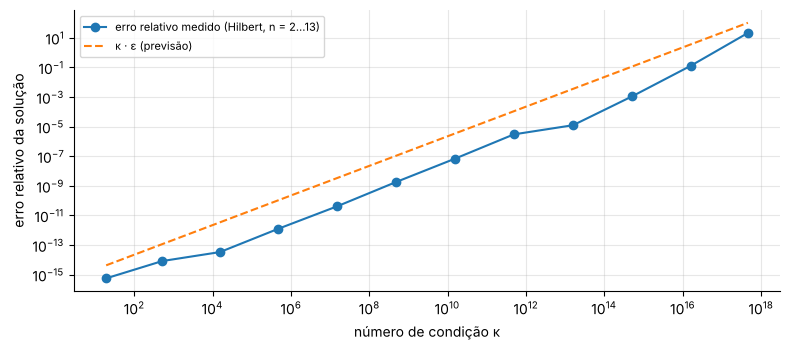

In [3]:
linhas = []
for k_mole in [100.0, 1.0, 1e-3, 1e-6, 1e-9]:
    Km = rigidez([k_mole, 50.0, 80.0, k_mole])        # as molas presas às paredes vão ficando moles
    linhas.append((k_mole, np.linalg.cond(Km)))
print("molas das paredes (N/m)   número de condição   dígitos perdidos (≈ log10 κ)")
for k_mole, kap in linhas:
    print(f"{k_mole:21.0e}   {kap:18.2e}   {np.log10(kap):8.1f}")
w, V = np.linalg.eigh(rigidez([1e-9, 50.0, 80.0, 1e-9]))
print("autovetor do menor autovalor (molas das paredes = 1e-9):", np.round(V[:, 0] / V[0, 0], 6), " ← os três blocos andam juntos")

# matriz de Hilbert: solução exata conhecida (x = 1), erro medido
ns = range(2, 14)
conds, erros = [], []
for n in ns:
    H = np.array([[1 / (i + j + 1) for j in range(n)] for i in range(n)])
    x_ver = np.ones(n)
    x_cal = np.linalg.solve(H, H @ x_ver)
    conds.append(np.linalg.cond(H)); erros.append(np.linalg.norm(x_cal - x_ver) / np.linalg.norm(x_ver))
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.loglog(conds, erros, "o-", label="erro relativo medido (Hilbert, n = 2…13)")
ax.loglog(conds, np.array(conds) * np.finfo(float).eps, "--", label="κ · ε (previsão)")
ax.set_xlabel("número de condição κ"); ax.set_ylabel("erro relativo da solução"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Leitura.** O erro medido acompanha a previsão $\kappa\,\varepsilon_M$, às vezes ficando bem abaixo dela (a regra é um limite superior). Com $n=13$, $\kappa\approx10^{18}$ e a solução não tem nenhum dígito correto, embora o algoritmo não tenha "errado" nada: é o **problema** que é instável, não o método. No sistema de molas, $\kappa$ cresce como $1/k_{\text{parede}}$: com molas de parede de $10^{-9}$ N/m perdem-se uns 11 dígitos, e o autovetor do menor autovalor é $(1,1,1)$, os três blocos andando juntos. A física avisa o que a matemática confirma: se nada segura o conjunto, a posição dele não está bem definida.

> **Nota: condicionamento e Kalman.** No filtro de Kalman, a matriz $\mathbf S=\mathbf H\mathbf P\mathbf H^\top+\mathbf R$ precisa ser "invertida" a cada passo. Se o sensor é muito preciso ($\mathbf R$ pequeno) e a incerteza é grande numa direção e pequena em outra, $\mathbf S$ fica mal condicionada. É uma das razões para preferir `solve` a `inv`.

---

## 3. Uma equação não linear: a mola que endurece

Uma mola real costuma **endurecer** quando muito esticada: a força passa a ser $F(x)=kx+k_3x^3$ (a "mola de Duffing"). Qual deslocamento $x$ equilibra uma força $F_0$? É preciso resolver

$$g(x)=kx+k_3x^3-F_0=0 .$$

Três métodos:
- **bisseção:** parte de um intervalo onde $g$ muda de sinal e o corta ao meio a cada passo. É lenta (ganha um bit por passo), mas não falha;
- **Newton:** substitui $g$ pela sua reta tangente e resolve a equação linear, $x_{n+1}=x_n-g(x_n)/g'(x_n)$. Perto da solução, o número de dígitos corretos **dobra** a cada passo (convergência quadrática), mas precisa da derivada e pode divergir se começar longe;
- **secante:** Newton com a derivada trocada pela inclinação entre os dois últimos pontos. Ordem $\approx1{,}618$ (a razão áurea), sem precisar da derivada.

raiz exata: -1/(150*(1/200 + sqrt(2049)/9000)**(1/3)) + (1/200 + sqrt(2049)/9000)**(1/3) ≈ 0.1847419037832733 m


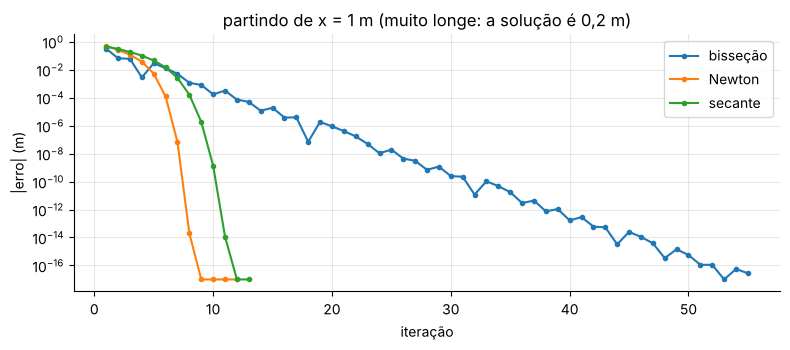

bisseção : ordem estimada nas últimas iterações ≈ 1.10
Newton   : ordem estimada nas últimas iterações ≈ 2.00
secante  : ordem estimada nas últimas iterações ≈ 1.62
OK   Newton chega à raiz exata:  diferença máxima = 0.00e+00
OK   sympy.nsolve concorda:  diferença máxima = 0.00e+00


In [4]:
k, k3, F0 = 100.0, 5000.0, 50.0
g  = lambda x: k * x + k3 * x**3 - F0
dg = lambda x: k + 3 * k3 * x**2

# solução de referência: a raiz real exata (fórmula de Cardano, pelo sympy)
xs = sp.Symbol("x", real=True)
raiz_exata = [r for r in sp.solve(sp.Integer(100) * xs + 5000 * xs**3 - 50, xs) if r.is_real][0]
x_ref = float(sp.N(raiz_exata, 30))
print("raiz exata:", sp.nsimplify(raiz_exata), "≈", f"{x_ref:.16f} m")

def bissecao(g, a, b, n):
    hist = []
    for _ in range(n):
        m = (a + b) / 2; hist.append(m)
        a, b = (a, m) if g(a) * g(m) <= 0 else (m, b)
    return hist

def newton(g, dg, x, n):
    hist = []
    for _ in range(n):
        x = x - g(x) / dg(x); hist.append(x)
    return hist

def secante(g, x0, x1, n):
    hist = []
    for _ in range(n):
        if g(x1) == g(x0):
            break
        x0, x1 = x1, x1 - g(x1) * (x1 - x0) / (g(x1) - g(x0)); hist.append(x1)
    return hist

H = {"bisseção": bissecao(g, 0.0, 1.0, 55), "Newton": newton(g, dg, 1.0, 12), "secante": secante(g, 1.0, 0.9, 14)}
fig, ax = plt.subplots(figsize=(8, 3.6))
for nome, h in H.items():
    e = np.abs(np.array(h) - x_ref)
    ax.semilogy(range(1, len(e) + 1), np.maximum(e, 1e-17), "o-", ms=3, label=nome)
ax.set_xlabel("iteração"); ax.set_ylabel("|erro| (m)"); ax.legend(); ax.set_title("partindo de x = 1 m (muito longe: a solução é 0,2 m)")
plt.tight_layout(); plt.show()

for nome, h in H.items():
    e = np.abs(np.array(h) - x_ref); e = e[(e > 1e-14) & (e < 1e-2)]
    if len(e) >= 3:
        ordem = np.log(e[2:] / e[1:-1]) / np.log(e[1:-1] / e[:-2])
        print(f"{nome:9s}: ordem estimada nas últimas iterações ≈ {np.median(ordem[-3:]):.2f}")
confere("Newton chega à raiz exata", H["Newton"][-1], x_ref, tol=1e-15)
confere("sympy.nsolve concorda", float(sp.nsolve(100 * xs + 5000 * xs**3 - 50, xs, 0.1)), x_ref, tol=1e-15)

**Leitura.**
- A bisseção desce em linha reta no gráfico semilog: ganha um bit (um fator 2) por iteração e precisa de uns 50 passos.
- Newton passeia um pouco no começo, porque partiu de longe, e depois **mergulha**: a ordem estimada perto de 2 é a convergência quadrática. Com 7 ou 8 iterações já está no limite da precisão do `float`.
- A secante fica no meio, com ordem perto de 1,6.

**Newton também falha.** Para $g(x)=\arctan x$, partindo de $x_0=1{,}5$, cada passo de Newton vai mais longe que o anterior. A célula abaixo mostra isso; é por essa razão que solucionadores robustos misturam Newton com bisseção ou "amortecem" o passo.

In [5]:
x = 1.5
for i in range(5):
    x = x - np.arctan(x) * (1 + x**2)
    print(f"Newton em arctan, iteração {i + 1}: x = {x:12.3f}")

Newton em arctan, iteração 1: x =       -1.694
Newton em arctan, iteração 2: x =        2.321
Newton em arctan, iteração 3: x =       -5.114
Newton em arctan, iteração 4: x =       32.296
Newton em arctan, iteração 5: x =    -1575.317


---

## 4. Sistemas não lineares: dois blocos e molas que endurecem

Dois blocos entre duas paredes, ligados por três molas de Duffing. Com $u_1=x_1$, $u_2=x_2-x_1$ e $u_3=-x_2$ os alongamentos das molas e $F(u)=ku+k_3u^3$, o equilíbrio é

$$\mathbf g(\mathbf x)=\begin{bmatrix}F(u_1)-F(u_2)-f_1\\F(u_2)-F(u_3)-f_2\end{bmatrix}=\mathbf 0 .$$

**Newton em várias variáveis.** A reta tangente vira o **jacobiano** $\mathbf J=\partial\mathbf g/\partial\mathbf x$, e cada passo resolve um **sistema linear** (seção 1):

$$\mathbf J(\mathbf x_n)\,\Delta\mathbf x=-\mathbf g(\mathbf x_n),\qquad \mathbf x_{n+1}=\mathbf x_n+\Delta\mathbf x .$$

Esta é a ideia que atravessa toda a série: **um problema não linear vira uma sequência de problemas lineares**. O jacobiano é calculado de três maneiras: à mão, pelo `sympy` e por diferenças finitas.

In [6]:
kk, kk3 = 100.0, 5000.0
f1, f2 = 30.0, -20.0
Fm  = lambda u: kk * u + kk3 * u**3
dFm = lambda u: kk + 3 * kk3 * u**2

def g2(x):
    u1, u2, u3 = x[0], x[1] - x[0], -x[1]
    return np.array([Fm(u1) - Fm(u2) - f1, Fm(u2) - Fm(u3) - f2])

def J2(x):  # à mão, pela regra da cadeia
    u1, u2, u3 = x[0], x[1] - x[0], -x[1]
    return np.array([[dFm(u1) + dFm(u2), -dFm(u2)],
                     [-dFm(u2),          dFm(u2) + dFm(u3)]])

# jacobiano simbólico
X1, X2 = sp.symbols("x1 x2", real=True)
Fs = lambda u: 100 * u + 5000 * u**3
gs = sp.Matrix([Fs(X1) - Fs(X2 - X1) - 30, Fs(X2 - X1) - Fs(-X2) + 20])
Js = gs.jacobian([X1, X2])
print("jacobiano simbólico:"); sp.pprint(sp.simplify(Js))

def jac_numerico(g, x, h=1e-6):
    return np.column_stack([(g(x + e) - g(x - e)) / (2 * h) for e in np.eye(len(x)) * h])

x = np.array([0.3, -0.2])
confere("jacobiano à mão = sympy", J2(x), np.array(Js.subs({X1: 0.3, X2: -0.2}), dtype=float), tol=1e-12)
confere("jacobiano à mão = diferenças finitas", J2(x), jac_numerico(g2, x), tol=1e-5, relativo=True)

x = np.zeros(2); hist = [x.copy()]
for it in range(10):
    dx = np.linalg.solve(J2(x), -g2(x))
    x = x + dx; hist.append(x.copy())
    print(f"iteração {it + 1}: x = {x},  |g(x)| = {np.linalg.norm(g2(x)):.2e}")
    if np.linalg.norm(dx) < 1e-14:
        break
confere("Newton = scipy.optimize.fsolve", x, optimize.fsolve(g2, np.zeros(2), fprime=J2, xtol=1e-14), tol=1e-12)
confere("Newton = sympy.nsolve (30 dígitos)", x, np.array(sp.nsolve(gs, [X1, X2], [0, 0], prec=30), dtype=float).ravel(), tol=1e-14)

jacobiano simbólico:


⎡        2                  2                              2           ⎤
⎢15000⋅x₁  + 15000⋅(x₁ - x₂)  + 200       - 15000⋅(x₁ - x₂)  - 100     ⎥
⎢                                                                      ⎥
⎢                      2                     2                  2      ⎥
⎣     - 15000⋅(x₁ - x₂)  - 100       15000⋅x₂  + 15000⋅(x₁ - x₂)  + 200⎦
OK   jacobiano à mão = sympy:  diferença máxima = 0.00e+00
OK   jacobiano à mão = diferenças finitas:  diferença relativa máxima = 4.72e-11
iteração 1: x = [ 0.133333 -0.033333],  |g(x)| = 4.21e+01
iteração 2: x = [ 0.098765 -0.024691],  |g(x)| = 7.75e+00
iteração 3: x = [ 0.088953 -0.022238],  |g(x)| = 4.89e-01
iteração 4: x = [ 0.088245 -0.022061],  |g(x)| = 2.37e-03
iteração 5: x = [ 0.088242 -0.02206 ],  |g(x)| = 5.60e-08
iteração 6: x = [ 0.088242 -0.02206 ],  |g(x)| = 0.00e+00
iteração 7: x = [ 0.088242 -0.02206 ],  |g(x)| = 0.00e+00
OK   Newton = scipy.optimize.fsolve:  diferença máxima = 3.47e-18
OK   Newton = sympy.nso

---

## 5. Mais equações que incógnitas: mínimos quadrados e Gauss–Newton

Num laboratório, não conhecemos $k$ e $k_3$: penduramos pesos, medimos os alongamentos, e as medidas têm ruído. Com $m$ medidas $(x_i,F_i)$ e só dois parâmetros, o sistema

$$F_i=k\,x_i+k_3\,x_i^3,\qquad i=1,\dots,m$$

tem **mais equações que incógnitas** e, por causa do ruído, nenhuma solução exata. Procura-se o $(k,k_3)$ que minimiza a soma dos quadrados dos resíduos.

**Repare:** a força é não linear em $x$, mas é **linear nos parâmetros**. Então é um problema de mínimos quadrados **lineares**, $\mathbf A\boldsymbol\theta\approx\mathbf F$, com as colunas $\mathbf A=[\,x_i\ \ x_i^3\,]$. A solução satisfaz as **equações normais** $\mathbf A^\top\mathbf A\,\boldsymbol\theta=\mathbf A^\top\mathbf F$; na prática, usa-se a decomposição QR (`lstsq`), porque $\kappa(\mathbf A^\top\mathbf A)=\kappa(\mathbf A)^2$.

**Agora um problema não linear nos parâmetros.** Suponha que a régua não estava zerada: as medidas de posição têm um deslocamento desconhecido $x_0$, e $F_i=k(x_i-x_0)+k_3(x_i-x_0)^3$. Agora $x_0$ entra de forma não linear. **Gauss–Newton** lineariza o resíduo em torno da estimativa atual e resolve um problema de mínimos quadrados lineares a cada passo:

$$\boldsymbol\theta_{n+1}=\boldsymbol\theta_n+\arg\min_{\Delta}\|\mathbf r(\boldsymbol\theta_n)+\mathbf J_n\Delta\|^2 .$$

> **Nota: o elo com a série Kalman.** O passo de correção do filtro de Kalman é um problema de mínimos quadrados (a medida nova contra a predição), e o **filtro de Kalman iterado** é exatamente Gauss–Newton (notebooks 1, 3 e 5 da série Kalman). O que se aprende aqui reaparece na etapa (d).

OK   equações normais = lstsq (QR):  diferença relativa máxima = 1.37e-15
κ(A) = 5.4e+01;   κ(AᵀA) = 2.9e+03  (= κ(A)²)
Gauss–Newton convergiu em 7 iterações; soma dos quadrados: 37.477 → 11.192
OK   Gauss–Newton = scipy.optimize.least_squares:  diferença relativa máxima = 1.65e-11

                         k (N/m)   k3 (N/m³)   x0 (mm)
verdadeiro                 100.0        5000     15.00
sem x0 (linear)            116.0        3654      0.00
com x0 (Gauss–Newton)      100.2        5004     15.17


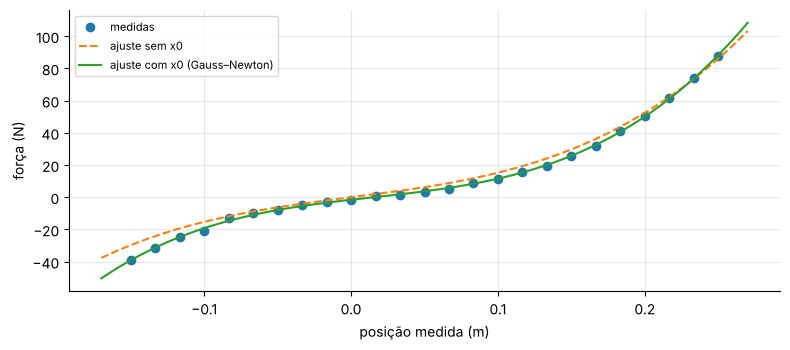

In [7]:
k_v, k3_v, x0_v, sig_F = 100.0, 5000.0, 0.015, 0.8
x_med = np.linspace(-0.15, 0.25, 25)
F_med = k_v * (x_med - x0_v) + k3_v * (x_med - x0_v)**3 + sig_F * rng.standard_normal(x_med.size)

# (i) ignorando x0: mínimos quadrados LINEARES em (k, k3)
A = np.column_stack([x_med, x_med**3])
th_normais = np.linalg.solve(A.T @ A, A.T @ F_med)
th_lstsq = np.linalg.lstsq(A, F_med, rcond=None)[0]
confere("equações normais = lstsq (QR)", th_normais, th_lstsq, tol=1e-8, relativo=True)
print(f"κ(A) = {np.linalg.cond(A):.1e};   κ(AᵀA) = {np.linalg.cond(A.T @ A):.1e}  (= κ(A)²)")

# (ii) com x0: Gauss–Newton em (k, k3, x0)
def residuo(th):
    k_, k3_, x0_ = th; u = x_med - x0_
    return k_ * u + k3_ * u**3 - F_med

def jac_res(th):
    k_, k3_, x0_ = th; u = x_med - x0_
    return np.column_stack([u, u**3, -(k_ + 3 * k3_ * u**2)])

th = np.array([*th_lstsq, 0.0]); hist = []
for it in range(20):
    J = jac_res(th)
    delta = np.linalg.lstsq(J, -residuo(th), rcond=None)[0]   # um problema LINEAR por passo
    th = th + delta; hist.append(np.sum(residuo(th)**2))
    if np.linalg.norm(delta) < 1e-12 * np.linalg.norm(th):
        break
print(f"Gauss–Newton convergiu em {it + 1} iterações; soma dos quadrados: {hist[0]:.3f} → {hist[-1]:.3f}")
ref = optimize.least_squares(residuo, [*th_lstsq, 0.0], jac=jac_res, xtol=1e-15, ftol=1e-15, gtol=1e-15).x
confere("Gauss–Newton = scipy.optimize.least_squares", th, ref, tol=1e-9, relativo=True)

tab = {"verdadeiro": [k_v, k3_v, x0_v], "sem x0 (linear)": [*th_lstsq, 0.0], "com x0 (Gauss–Newton)": list(th)}
print(f"\n{'':22s}{'k (N/m)':>10s}{'k3 (N/m³)':>12s}{'x0 (mm)':>10s}")
for nome, (a1, a2, a3) in tab.items():
    print(f"{nome:22s}{a1:10.1f}{a2:12.0f}{1000 * a3:10.2f}")

xx = np.linspace(-0.17, 0.27, 200)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(x_med, F_med, "o", label="medidas")
ax.plot(xx, th_lstsq[0] * xx + th_lstsq[1] * xx**3, "--", label="ajuste sem x0")
ax.plot(xx, th[0] * (xx - th[2]) + th[1] * (xx - th[2])**3, label="ajuste com x0 (Gauss–Newton)")
ax.set_xlabel("posição medida (m)"); ax.set_ylabel("força (N)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Leitura.** Ignorar o deslocamento $x_0$ da régua distorce os dois coeficientes, porque o modelo errado tenta compensar o deslocamento curvando a cúbica. Com $x_0$ no modelo, Gauss–Newton recupera os três parâmetros em poucas iterações, e concorda com o `scipy` até a precisão da máquina. A soma dos quadrados cai a cada passo.

---

## 6. Exercícios

1. **Algoritmo de Thomas.** Escreva a eliminação de Gauss especializada para matrizes tridiagonais, com custo $O(n)$, e compare o tempo com `np.linalg.solve` para $n=10^3$ e $10^4$ blocos.
2. **Sem pivotamento.** Resolva $\begin{bmatrix}10^{-17}&1\\1&1\end{bmatrix}\mathbf x=\begin{bmatrix}1\\2\end{bmatrix}$ com a eliminação **sem** troca de linhas. Explique o resultado.
3. **Bacia de atração.** Para a mola de Duffing com $k<0$ (uma mola "invertida", com dois pontos de equilíbrio estáveis), pinte o eixo $x_0$ conforme a raiz para a qual Newton converge. (No domínio IV, a mesma figura no plano complexo vira um fractal.)
4. **Newton amortecido.** Modifique o Newton da seção 3 para, quando $|g|$ não diminuir, cortar o passo ao meio. Ele passa a convergir para $\arctan x$ a partir de $x_0=1{,}5$?
5. **Incerteza dos parâmetros.** Na seção 5, a covariância dos parâmetros estimados é aproximadamente $\sigma_F^2(\mathbf J^\top\mathbf J)^{-1}$. Calcule-a, e confira por Monte Carlo (repita o experimento com 500 ruídos diferentes). Esta é a mesma matriz $\mathbf P$ do filtro de Kalman.